In [1]:
import pandas as pd
import numpy as np

file_path = r"C:\Users\nadip\Downloads\archive (3)\WineQT.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1    

In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

Dataset shape: (1143, 13)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null

In [3]:
from sklearn.preprocessing import MinMaxScaler

numeric_df = df.select_dtypes(include=np.number)

scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(numeric_df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)

print(normalized_df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0       0.247788          0.397260         0.00        0.068493   0.106845   
1       0.283186          0.520548         0.00        0.116438   0.143573   
2       0.283186          0.438356         0.04        0.095890   0.133556   
3       0.584071          0.109589         0.56        0.068493   0.105175   
4       0.247788          0.397260         0.00        0.068493   0.106845   

   free sulfur dioxide  total sulfur dioxide   density        pH  sulphates  \
0             0.149254              0.098940  0.567548  0.606299   0.137725   
1             0.358209              0.215548  0.494126  0.362205   0.209581   
2             0.208955              0.169611  0.508811  0.409449   0.191617   
3             0.238806              0.190813  0.582232  0.330709   0.149701   
4             0.149254              0.098940  0.567548  0.606299   0.137725   

    alcohol  quality        Id  
0  0.153846      0.4  0

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
standardized_data = scaler.fit_transform(numeric_df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_df.columns
)

print(standardized_df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0      -0.521580          0.939332    -1.365027       -0.466421  -0.231395   
1      -0.292593          1.941813    -1.365027        0.050060   0.234247   
2      -0.292593          1.273492    -1.161568       -0.171289   0.107253   
3       1.653789         -1.399789     1.483400       -0.466421  -0.252560   
4      -0.521580          0.939332    -1.365027       -0.466421  -0.231395   

   free sulfur dioxide  total sulfur dioxide   density        pH  sulphates  \
0            -0.450467             -0.363610  0.555854  1.270695  -0.573658   
1             0.915920              0.643477  0.036165 -0.708928   0.130881   
2            -0.060071              0.246745  0.140103 -0.325775  -0.045254   
3             0.135127              0.429852  0.659792 -0.964363  -0.456235   
4            -0.450467             -0.363610  0.555854  1.270695  -0.573658   

    alcohol   quality        Id  
0 -0.963382 -0.815724 

   Principal Component 1  Principal Component 2
0              -1.215133              -1.794555
1              -0.467435              -2.477990
2              -0.401695              -1.871949
3               2.645247               0.100493
4              -1.216916              -1.792910

Explained variance ratio:
[0.25192323 0.17625364]


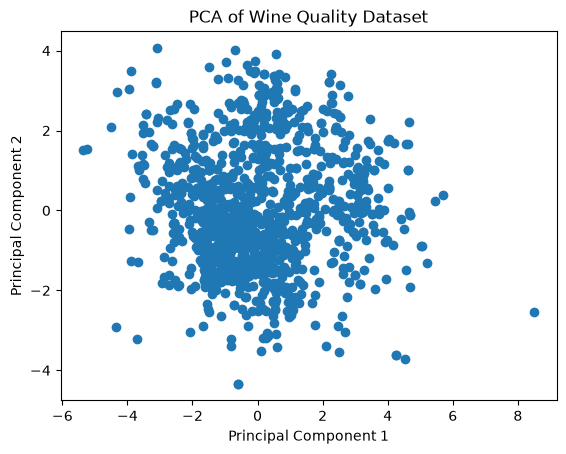

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Standardize the numerical data
X_scaled = StandardScaler().fit_transform(numeric_df)

# Reduce features to 2 components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["Principal Component 1", "Principal Component 2"]
)

print(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

# Plot PCA results
plt.scatter(
    pca_df["Principal Component 1"],
    pca_df["Principal Component 2"]
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Wine Quality Dataset")
plt.show()

In [6]:
column = "alcohol"

Q1 = df[column].quantile(0.25)
Q3 = df[column].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df[column] < lower_limit) |
    (df[column] > upper_limit)
]

print("Number of outliers:", len(outliers))
print(outliers.head())

Number of outliers: 12
     fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
96             5.2              0.34         0.00             1.8      0.050   
98             5.2              0.34         0.00             1.8      0.050   
329            8.8              0.46         0.45             2.6      0.065   
419            5.0              0.42         0.24             2.0      0.060   
462           15.9              0.36         0.65             7.5      0.096   

     free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
96                  27.0                  63.0   0.9916  3.68       0.79   
98                  27.0                  63.0   0.9916  3.68       0.79   
329                  7.0                  18.0   0.9947  3.32       0.79   
419                 19.0                  50.0   0.9917  3.72       0.74   
462                 22.0                  71.0   0.9976  2.98       0.84   

     alcohol  quality   Id  
96      14